# Анализ рынка заведений общественного питания Москвы

## Цель исследования

Инвестиционный фонд Shut Up and Take My Money планирует выйти в новую для себя область и открыть заведение общественного питания в Москве. На текущем этапе формат заведения еще не определен: рассматриваются разные варианты, включая кафе, ресторан или бар. Также предстоит выбрать расположение, ценовую политику и другие характеристики будущего заведения.

Перед принятием решения необходимо изучить рынок общественного питания Москвы: его структуру, представленность разных категорий заведений, особенности их расположения, уровень цен, рейтинги, распространенность сетевых заведений и другие характеристики.

Цель исследования — провести анализ рынка общественного питания Москвы и определить его основные особенности, которые могут быть полезны инвесторам при выборе концепции будущего заведения.

Для исследования используются данные сервисов Яндекс Карты и Яндекс Бизнес за лето 2022 года. Данные носят справочный характер, поскольку информация в Яндекс Бизнес могла быть добавлена пользователями или получена из общедоступных источников.

## Описание данных

Файл **`rest_info.csv`** содержит информацию о заведениях общественного питания:
- `name` — название заведения;
- `address` — адрес заведения;
- `district` — административный район, в котором находится заведение, например Центральный административный округ;
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- `hours` — информация о днях и часах работы;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
- `chain` — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
0 — заведение не является сетевым;
1 — заведение является сетевым.
- `seats` — количество посадочных мест.

---
Файл **`rest_price.csv`** содержит информацию о среднем чеке в заведениях общественного питания:
- `price` — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- `avg_bill` — строка, которая хранит среднюю стоимость заказа в виде диапазона, например:
«Средний счёт: 1000–1500 ₽»;
«Цена чашки капучино: 130–220 ₽»;
«Цена бокала пива: 400–600 ₽».
и так далее;
- `middle_avg_bill` — число с оценкой среднего чека, которое указано только для значений из столбца `avg_bill`, начинающихся с подстроки «Средний счёт»:
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.
- `middle_coffee_cup` — число с оценкой одной чашки капучино, которое указано только для значений из столбца `avg_bill`, начинающихся с подстроки «Цена одной чашки капучино»:
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.

## Этапы исследования

**[1. Загрузка и первичный анализ данных](#section-1)**

* [1.1. Изучение структуры данных](#section-1-1)
* [1.2. Объединение данных](#section-1-2)

**[2. Предобработка данных](#section-2)**

* [2.1. Проверка типов данных и пропусков](#section-2-1)
* [2.2. Проверка и обработка дубликатов](#section-2-2)
* [2.3. Создание признака круглосуточной работы](#section-2-3)

**[3. Исследовательский анализ данных](#section-3)**

* [3.1. Анализ категорий заведений](#section-3-1)
* [3.2. Анализ заведений по административным округам](#section-3-2)
* [3.3. Анализ сетевых и несетевых заведений](#section-3-3)
* [3.4. Анализ количества посадочных мест](#section-3-4)
* [3.5. Анализ рейтингов заведений](#section-3-5)
* [3.6. Анализ факторов, связанных с рейтингом](#section-3-6)
* [3.7. Анализ популярных сетей Москвы](#section-3-7)
* [3.8. Анализ среднего чека по АО Москвы](#section-3-8)

**[4. Итоговые выводы и рекомендации](#section-4)**

* [Результаты проведенного анализа](#section-4-1)
* [Основные выводы](#section-4-2)
* [Рекомендации](#section-4-3)

<a id="section-1"></a>
## 1. Загрузка и первичный анализ данных

На первом этапе загрузим исходные данные и изучим их структуру, типы данных и наличие пропусков. После этого объединим два датасета в одну таблицу для дальнейшего анализа.

In [1]:
# Импорт библиотек
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display
from phik import phik_matrix

<a id="section-1-1"></a>
### 1.1. Изучение структуры данных

In [2]:
# Загрузим исходные данные
rest_info = pd.read_csv('rest_info.csv')
rest_price = pd.read_csv('rest_price.csv')

In [3]:
# Выведем первые 5 строк датасета rest_info, информацию о пропусках и типах данных в столбцах
display(Markdown('**Первые 5 строк `rest_info`**'))
display(rest_info.head())

display(Markdown('**Общая информация о `rest_info`**'))
rest_info.info()

**Первые 5 строк `rest_info`**

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


**Общая информация о `rest_info`**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


In [4]:
# Выведем первые 5 строк датасета rest_price, информацию о пропусках и типах данных в столбцах
display(Markdown('**Первые 5 строк `rest_price`**'))
display(rest_price.head())

display(Markdown('**Общая информация о `rest_price`**'))
rest_price.info()

**Первые 5 строк `rest_price`**

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


**Общая информация о `rest_price`**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


В `rest_info` содержится 8406 строк и 9 столбцов. Пропуски встречаются в `hours` и `seats`. Типы данных соответствуют содержимому столбцов, однако для некоторых числовых признаков можно уменьшить размерность.

В `rest_price` содержится 4058 строк и 5 столбцов. Пропуски есть в `price`, `avg_bill`, `middle_avg_bill` и `middle_coffee_cup`. Их наличие частично связано со структурой данных: например, `middle_avg_bill` заполняется только для записей со средним счетом, а `middle_coffee_cup` — для записей с информацией о стоимости капучино.

На этапе предобработки подробнее изучим пропуски, проверим дубликаты и при необходимости скорректируем типы данных.

<a id="section-1-2"></a>
### 1.2. Объединение данных

Объединим данные о заведениях и ценах по идентификатору `id`. В качестве основной таблицы используем `rest_info`, чтобы сохранить все содержащиеся в ней заведения.

In [5]:
# Объединим датасеты rest_info и rest_price по ключу id
rest = pd.merge(rest_info, rest_price, on='id', how='left')

In [6]:
# Выведем первые 5 строк объединенного датасета и информацию о нем
display(Markdown('**Первые 5 строк объединенного датасета `rest`**'))
display(rest.head())

display(Markdown('**Общая информация об объединенном датасете `rest`**'))
rest.info()

**Первые 5 строк объединенного датасета `rest`**

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN


**Общая информация об объединенном датасете `rest`**

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 919.4+ KB


<a id="section-2"></a>
## 2. Предобработка данных

На этом этапе проверим типы данных и пропуски, обработаем дубликаты и создадим признак круглосуточной работы заведений.

<a id="section-2-1"></a>
### 2.1. Проверка типов данных и пропусков

In [7]:
# Понизим размерность числовых данных
for column in ['rating', 'seats', 'middle_avg_bill', 'middle_coffee_cup']: 
    rest[column] = pd.to_numeric(rest[column], downcast='float')

rest['chain'] = pd.to_numeric(rest['chain'], downcast='integer')

In [8]:
# Выведем результаты преобразования типов данных
display(Markdown('**Общая информация после преобразования типов данных**'))
rest.info()

**Общая информация после преобразования типов данных**

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float32
 7   chain              8406 non-null   int8   
 8   seats              4795 non-null   float32
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float32
 12  middle_coffee_cup  535 non-null    float32
dtypes: float32(4), int8(1), object(8)
memory usage: 730.6+ KB


In [9]:
missing_values = pd.DataFrame({
    'Количество пропусков': rest.isna().sum(),
    'Доля пропусков, %': round(rest.isna().mean() * 100, 1)
})

display(Markdown('**Пропуски в данных**'))
display(missing_values)

**Пропуски в данных**

,Количество пропусков,"Доля пропусков, %"
id,0,0.0
name,0,0.0
category,0,0.0
address,0,0.0
district,0,0.0
hours,536,6.4
rating,0,0.0
chain,0,0.0
seats,3611,43.0
price,5091,60.6


Пропуски распределены по столбцам неравномерно. В `hours` отсутствует 6.4% значений, в `seats` — 43%. В признаках, связанных с ценами, доля пропусков значительно выше: от 54.6% в `avg_bill` до 93.6% в `middle_coffee_cup`.

Пропуски в `middle_avg_bill` и `middle_coffee_cup` частично связаны со структурой данных: эти столбцы заполняются только для определенных типов информации из `avg_bill`. Поэтому отсутствие значения здесь не всегда означает ошибку или потерю данных.

Заполнять пропуски расчетными значениями не будем, так как для этого нет достаточных оснований, а искусственная замена может исказить результаты анализа. Пропуски сохраним и будем учитывать при работе с отдельными признаками.

<a id="section-2-2"></a>
### 2.2. Проверка и обработка дубликатов

In [10]:
# Выведем кол-во явных дубликатов
print(f'Кол-во явных дубликатов строк в датасете: {rest.duplicated().sum()}')

Кол-во явных дубликатов строк в датасете: 0


In [11]:
unique_values = (
    rest[['name', 'category', 'address', 'district', 'price']]
    .nunique()
    .rename('Кол-во уникальных значений')
    .to_frame()
)

display(Markdown('**Количество уникальных значений в категориальных столбцах**'))
display(unique_values)

**Количество уникальных значений в категориальных столбцах**

,Кол-во уникальных значений
name,5614
category,8
address,5753
district,9
price,4


Повторяющиеся названия заведений сами по себе не являются дубликатами: одно название может использоваться несколькими заведениями или точками одной сети. Аналогично, по одному адресу могут находиться разные заведения.

Поэтому отдельно проверим значения категориальных признаков, а возможные дубликаты заведений будем искать по сочетанию названия и адреса.

In [12]:
for column in ['category', 'district', 'price']:
    display(Markdown(f'**Уникальные значения `{column}`**'))
    display(pd.Series(rest[column].dropna().unique(), name=column))

**Уникальные значения `category`**

0               кафе
1           ресторан
2            кофейня
3           пиццерия
4            бар,паб
5    быстрое питание
6           булочная
7           столовая
Name: category, dtype: object

**Уникальные значения `district`**

0            Северный административный округ
1    Северо-Восточный административный округ
2     Северо-Западный административный округ
3            Западный административный округ
4         Центральный административный округ
5           Восточный административный округ
6       Юго-Восточный административный округ
7               Южный административный округ
8        Юго-Западный административный округ
Name: district, dtype: object

**Уникальные значения `price`**

0    выше среднего
1          средние
2          высокие
3           низкие
Name: price, dtype: object

В `category`, `district` и `price` неявных дубликатов не обнаружено. Проверим возможные дубликаты заведений по сочетанию `name` и `address`.

In [13]:
# Нормализуем название и адрес
rest['name'] = rest['name'].str.lower().str.strip()
rest['address'] = rest['address'].str.lower().str.strip()

duplicates = rest.duplicated(subset=['name', 'address']).sum()

print(f'Количество дубликатов по сочетанию названия и адреса: {duplicates}')

Количество дубликатов по сочетанию названия и адреса: 4


In [14]:
# Избавимся от найденных неявных дубликатов
rest_clear = (
    rest
    .drop_duplicates(subset=['name', 'address'], keep='last')
    .copy())

print(
    'Количество дубликатов после очистки: '
    f"{rest_clear.duplicated(subset=['name', 'address']).sum()}")

Количество дубликатов после очистки: 0


Явных дубликатов в данных не обнаружено. По сочетанию нормализованных названия и адреса найдено 4 дубликата, которые были удалены.

<a id="section-2-3"></a>
### 2.3. Создание признака круглосуточной работы

In [15]:
rest_clear['is_24_7'] = (
    rest_clear['hours'] == 'ежедневно, круглосуточно')

count_24_7 = rest_clear['is_24_7'].sum()
share_24_7 = rest_clear['is_24_7'].mean() * 100

print(
    f'Количество круглосуточных заведений: {count_24_7} '
    f'({share_24_7:.1f}%)')

Количество круглосуточных заведений: 730 (8.7%)


### Итоги предобработки

В ходе предобработки была уменьшена размерность числовых типов данных и изучены пропуски. Заполнять пропущенные значения не стали, поскольку для части признаков они связаны со структурой исходных данных, а обоснованного способа восстановления остальных значений нет.

Явных дубликатов не обнаружено. После нормализации названий и адресов найдено и удалено 4 дубликата по сочетанию этих признаков.

Также был создан булевый признак `is_24_7`, который показывает, работает ли заведение ежедневно и круглосуточно.

In [16]:
# Отразим долю отфильтрованных данных
print(f'Доля данных, оставшихся после фильтрации: {round(rest_clear.shape[0] / rest.shape[0]*100, 2)}%')

# Далее будем работать с отфильтрованными данными
rest = rest_clear

Доля данных, оставшихся после фильтрации: 99.95%


<a id="section-3"></a>
## 3. Исследовательский анализ данных

Проведем исследовательский анализ рынка общественного питания Москвы. Рассмотрим структуру заведений по категориям и округам, распространенность сетевых форматов, количество посадочных мест, рейтинги и цены, а также изучим связи между отдельными характеристиками заведений.

<a id="section-3-1"></a>
### 3.1. Анализ категорий заведений

In [17]:
# Выведем кол-во заведений в разрезе категорий
rest_cat = pd.DataFrame(rest['category'].value_counts(ascending=False))
rest_cat.columns = ['Кол-во заведений']
rest_cat.index.name = 'Категория'
rest_cat

,Кол-во заведений
Категория,
кафе,2377
ресторан,2041
кофейня,1413
"бар,паб",765
пиццерия,633
быстрое питание,603
столовая,315
булочная,255


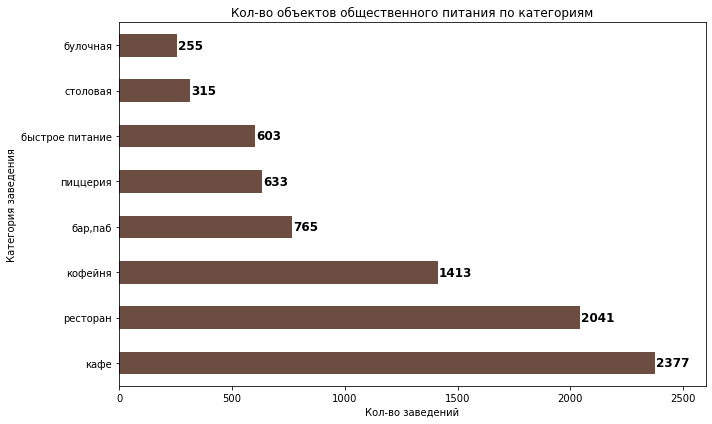

In [18]:
# Построим линейчатую диаграмму для визуализации полученных данных
ax = rest_cat.plot(
    kind='barh',
    title='Кол-во объектов общественного питания по категориям',
    color='#6D4C41',
    legend=False,
    figsize=(10, 6))

ax.set_xlabel('Кол-во заведений')
ax.set_ylabel('Категория заведения')

for i, value in enumerate(rest_cat['Кол-во заведений']):
    ax.text(
        value + 5, i, int(value),
        ha='left', va='center',
        fontweight='bold', fontsize=12)

plt.xlim(right=2600)
plt.tight_layout()
plt.show()

In [19]:
# Посчитаем долю кафе среди всех заведений
print(
    f"Доля кафе среди всех объектов общественного питания Москвы составляет "
    f"{round(rest_cat.loc['кафе', 'Кол-во заведений'] / rest_cat['Кол-во заведений'].sum() * 100)}%")

Доля кафе среди всех объектов общественного питания Москвы составляет 28%


Наиболее распространенными категориями являются кафе (2378 заведений), рестораны (2041) и кофейни (1413). Кафе составляют около 28% всех заведений в выборке. Реже всего встречаются булочные (255), столовые (315) и заведения быстрого питания (603).

<a id="section-3-2"></a>
### 3.2. Анализ заведений по административным округам

In [20]:
# Выведем кол-во заведений в разрезе административных районов Москвы
rest_dist = pd.DataFrame(rest['district'].value_counts(ascending=False))
rest_dist.columns = ['Кол-во заведений']
rest_dist.index.name = 'Административный округ'
rest_dist

,Кол-во заведений
Административный округ,
Центральный административный округ,2242
Северный административный округ,898
Южный административный округ,892
Северо-Восточный административный округ,890
Западный административный округ,850
Восточный административный округ,798
Юго-Восточный административный округ,714
Юго-Западный административный округ,709
Северо-Западный административный округ,409


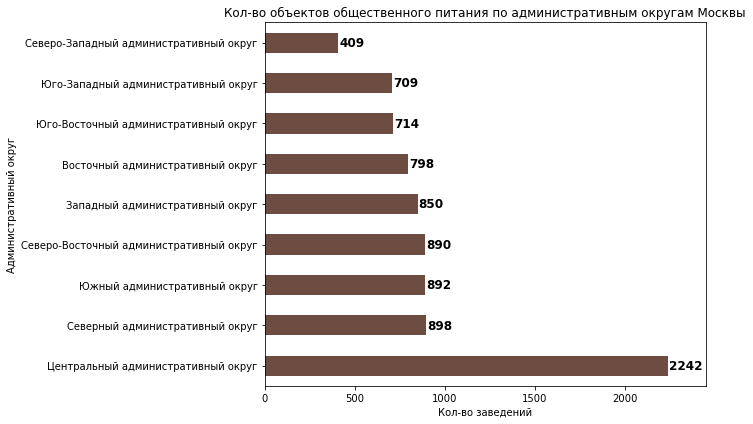

In [21]:
# Построим линейчатую диаграмму для визуализации полученных данных
ax = rest_dist.plot(
    kind='barh',
    title='Кол-во объектов общественного питания по административным округам Москвы',
    color='#6D4C41',
    legend=False,
    figsize=(10, 6))

ax.set_xlabel('Кол-во заведений')
ax.set_ylabel('Административный округ')

for i, value in enumerate(rest_dist['Кол-во заведений']):
    ax.text(
        value + 5, i, int(value),
        ha='left', va='center',
        fontweight='bold', fontsize=12)

plt.xlim(right=2450)
plt.tight_layout()
plt.show()

Наибольшее количество заведений расположено в Центральном административном округе — 2242 объекта. Это примерно в 2.5 раза больше, чем в Северном административном округе, который занимает второе место с 899 заведениями. Меньше всего объектов находится в Северо-Западном административном округе — 409.

Рассмотрим структуру заведений в ЦАО по категориям.

In [22]:
# Выведем кол-во заведений в разрезе категорий в центральном административном округе
rest_cat_central = pd.DataFrame(
    rest[rest['district'] == 'Центральный административный округ']['category']
    .value_counts(ascending=False))
rest_cat_central.columns = ['Кол-во заведений в ЦАО']
rest_cat_central.index.name = 'Категория'

display(rest_cat_central)

,Кол-во заведений в ЦАО
Категория,
ресторан,670
кафе,464
кофейня,428
"бар,паб",364
пиццерия,113
быстрое питание,87
столовая,66
булочная,50


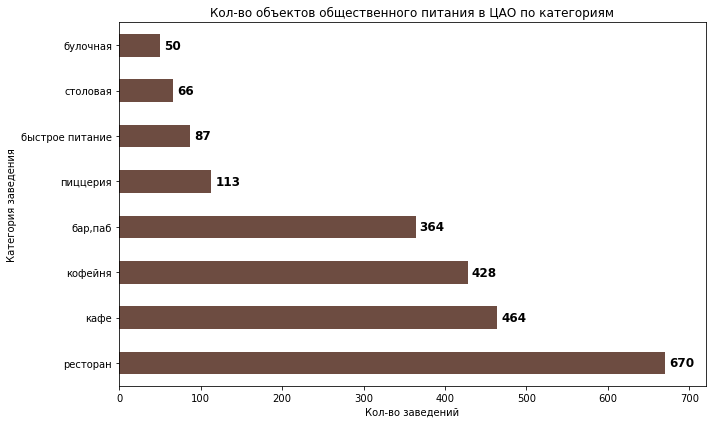

In [23]:
# Построим линейчатую диаграмму для визуализации полученных данных
ax = rest_cat_central.plot(
    kind='barh',
    title='Кол-во объектов общественного питания в ЦАО по категориям',
    color='#6D4C41',
    legend=False,
    xlabel='',
    figsize=(10, 6))

ax.set_xlabel('Кол-во заведений')
ax.set_ylabel('Категория заведения')

for i, value in enumerate(rest_cat_central['Кол-во заведений в ЦАО']):
    ax.text(
        value + 5, i, int(value),
        ha='left', va='center',
        fontweight='bold', fontsize=12)

plt.xlim(right=720)
plt.tight_layout()
plt.show()

В Центральном административном округе больше всего ресторанов — 670. Далее идут кафе, кофейни и бары/пабы, количество которых составляет от 364 до 464. Реже всего в центре встречаются пиццерии, заведения быстрого питания, столовые и булочные — от 50 до 113 объектов.

<a id="section-3-3"></a>
### 3.3. Анализ сетевых и несетевых заведений

In [24]:
# Выведем процент сетевых и не сетевых заведений
rest_chain = (pd.DataFrame(round(rest['chain']
              .value_counts(normalize=True, ascending=True)*100).astype('int64')))
rest_chain.columns = ['% заведений']
rest_chain.index = ['Сетевые', 'Несетевые']
rest_chain.index.name = 'Формат'
rest_chain

,% заведений
Формат,
Сетевые,38
Несетевые,62


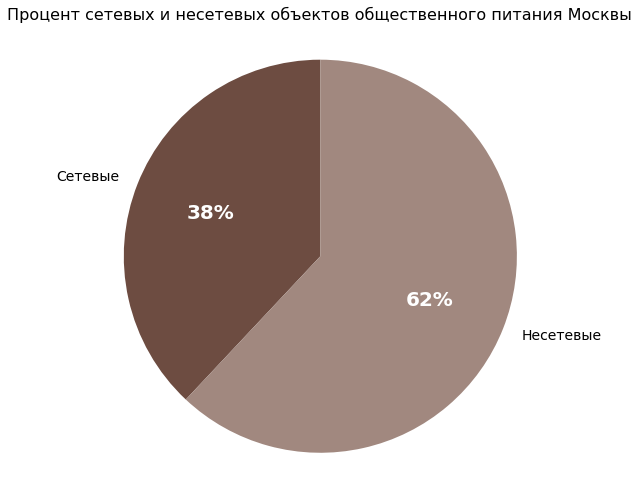

In [25]:
plt.figure(figsize=(10, 8))
colors = ['#6D4C41', '#A1887F']

wedges, texts, autotexts = plt.pie(rest_chain.values.flatten(), 
                                   labels=rest_chain.index, 
                                   autopct='%1.0f%%',
                                   colors=colors,
                                   startangle=90,
                                   textprops={'fontsize': 14})

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(20)

plt.title('Процент сетевых и несетевых объектов общественного питания Москвы', 
          fontsize=16, pad=20)
plt.axis('equal')
plt.show()

Несетевые заведения преобладают на рынке и составляют 62% выборки, тогда как на сетевые приходится 38%. Рассмотрим, как это соотношение меняется в зависимости от категории заведения.

In [26]:
# Выведем кол-во сетевых и несетевых заведений по категориям в абсолютных велечинах
rest_chain_cat = rest.pivot_table(
    index='category',
    columns='chain',
    values='id',
    aggfunc='count')

rest_chain_cat.columns = ['Несетевые', 'Сетевые']
rest_chain_cat.index.name = 'Категория'
rest_chain_cat = rest_chain_cat.sort_values(by='Сетевые', ascending=False)

display(rest_chain_cat)

,Несетевые,Сетевые
Категория,,
кафе,1598,779
ресторан,1311,730
кофейня,693,720
пиццерия,303,330
быстрое питание,371,232
"бар,паб",596,169
булочная,99,156
столовая,227,88


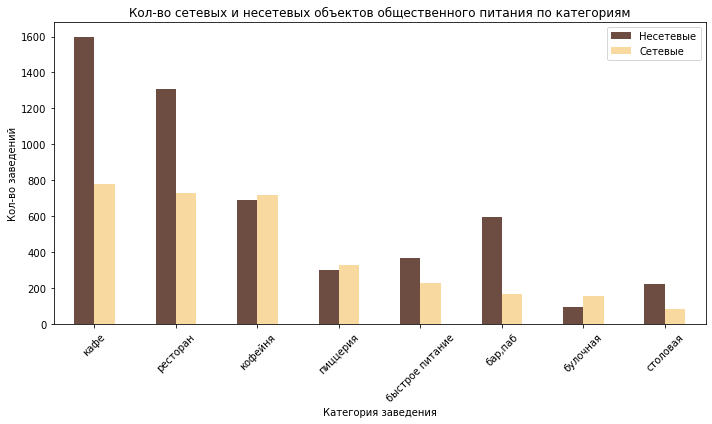

In [27]:
# Построим столбчатую диаграмму для визуализации полученных данных
rest_chain_cat.sort_values(by='Сетевые', ascending=False).plot(kind='bar', 
              title='Кол-во сетевых и несетевых объектов общественного питания по категориям', 
              legend=True,
              color=['#6D4C41', '#f8daa0'],
              figsize=(10, 6),
              rot=45)
plt.xlabel('Категория заведения')
plt.ylabel('Кол-во заведений')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

Несетевой формат особенно распространен среди кафе, столовых и баров/пабов. При этом в кофейнях, пиццериях и булочных количество сетевых заведений выше количества несетевых. Для более корректного сравнения категорий рассмотрим долю сетевых заведений внутри каждой из них.

In [28]:
rest_chain_1 = pd.DataFrame(
    rest.groupby('category')['chain']
    .mean()
    .sort_values(ascending=False))

rest_chain_1.columns = ['% сетевых заведений']
rest_chain_1['% сетевых заведений'] = (
    rest_chain_1['% сетевых заведений'] * 100
).round().astype('int64')
rest_chain_1.index.name = 'Категория'

display(rest_chain_1)

,% сетевых заведений
Категория,
булочная,61
пиццерия,52
кофейня,51
быстрое питание,38
ресторан,36
кафе,33
столовая,28
"бар,паб",22


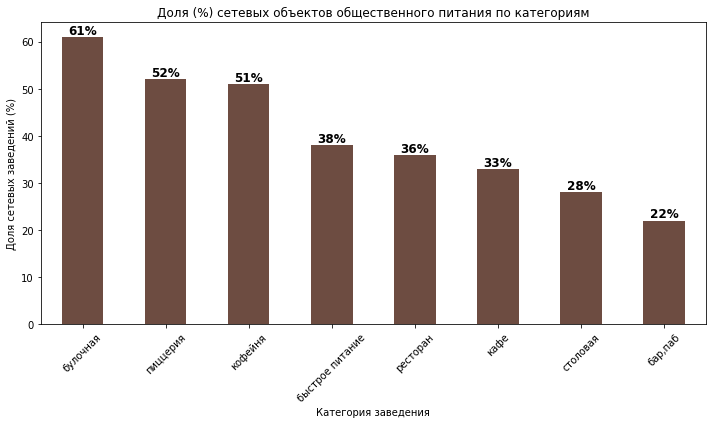

In [29]:
# Построим столбчатую диаграмму для визуализации доли (%) сетевых заведений
ax = rest_chain_1.plot(
    kind='bar',
    title='Доля (%) сетевых объектов общественного питания по категориям',
    color='#6D4C41',
    xlabel='',
    legend=False,
    figsize=(10, 6),
    rot=45)

ax.set_xlabel('Категория заведения')
ax.set_ylabel('Доля сетевых заведений (%)')

for i, value in enumerate(rest_chain_1['% сетевых заведений']):
    ax.text(
        i, value, f'{int(value)}%',
        ha='center', va='bottom',
        fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

Наибольшая доля сетевых заведений наблюдается среди булочных (61%), пиццерий (52%) и кофеен (51%). Это единственные категории, в которых сетевой формат преобладает над несетевым. Реже всего сетевыми являются бары/пабы (22%), столовые (28%) и кафе (33%).

<a id="section-3-4"></a>
### 3.4. Анализ количества посадочных мест

In [30]:
# Выведем информацию о статистиках для посадочных мест для изучения их распределения
display(Markdown('**Описательная статистика кол-ва посадочных мест**'))
display(pd.DataFrame(rest['seats'].describe()).round(2))

**Описательная статистика кол-ва посадочных мест**

,seats
count,4792.00
mean,108.36
std,122.84
min,0.00
25%,40.00
50%,75.00
75%,140.00
max,1288.00


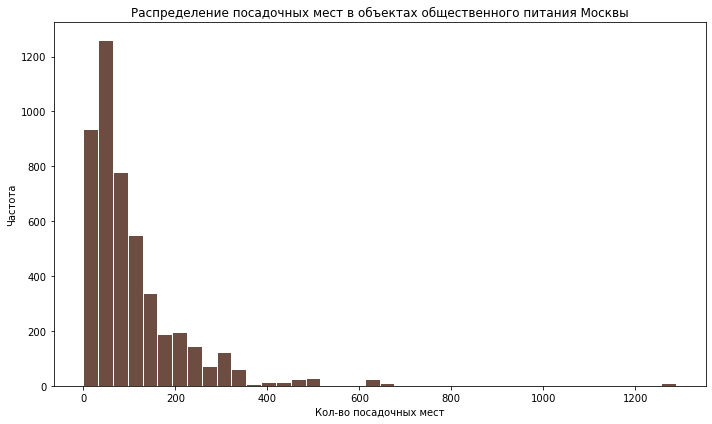

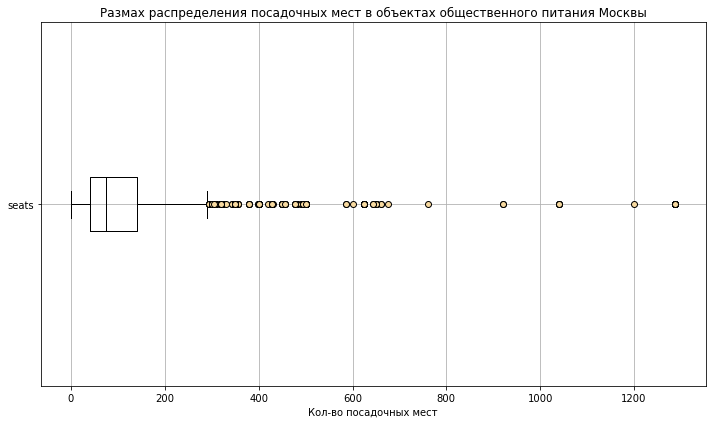

In [31]:
# Построим гистограмму распределения посадочных мест в заведениях
rest['seats'].plot(kind='hist',
                   title='Распределение посадочных мест в объектах общественного питания Москвы',
                   figsize=(10, 6),
                   color='#6D4C41',
                   edgecolor='white',
                   bins=40)
plt.xlabel('Кол-во посадочных мест')
plt.ylabel('Частота')
plt.tight_layout()
plt.show()

# Построим ящик с усами для изучения размаха распределения и выбросов
rest.boxplot(column='seats', 
             vert=False,
             figsize=(10, 6),
             color='black',
             flierprops={'marker': 'o',
                         'markerfacecolor': '#f8daa0'})
plt.xlabel('Кол-во посадочных мест')
plt.title('Размах распределения посадочных мест в объектах общественного питания Москвы')
plt.tight_layout()
plt.show()

Распределение количества посадочных мест имеет выраженный правосторонний скос и содержит много высоких значений. Среднее составляет 108 мест, медиана — 75, а максимальное значение достигает 1288 мест. Основная часть наблюдений находится в диапазоне от 40 до 140 посадочных мест.

Высокие значения могут быть связаны с особенностями формата или размера отдельных заведений, однако по имеющимся данным определить их причину нельзя. Из-за асимметрии распределения в качестве типичного значения будем использовать медиану.

In [32]:
# Выведем медианные значения кол-ва мест в разрезе категорий
rest_cat_seats = pd.DataFrame(
    rest.groupby('category')['seats']
    .median()
    .sort_values(ascending=False))

rest_cat_seats['seats'] = rest_cat_seats['seats'].astype('int64')
rest_cat_seats.columns = ['Медиана кол-ва мест']
rest_cat_seats.index.name = 'Категория'

display(rest_cat_seats)

,Медиана кол-ва мест
Категория,
ресторан,86
"бар,паб",82
кофейня,80
столовая,75
быстрое питание,65
кафе,60
пиццерия,55
булочная,50


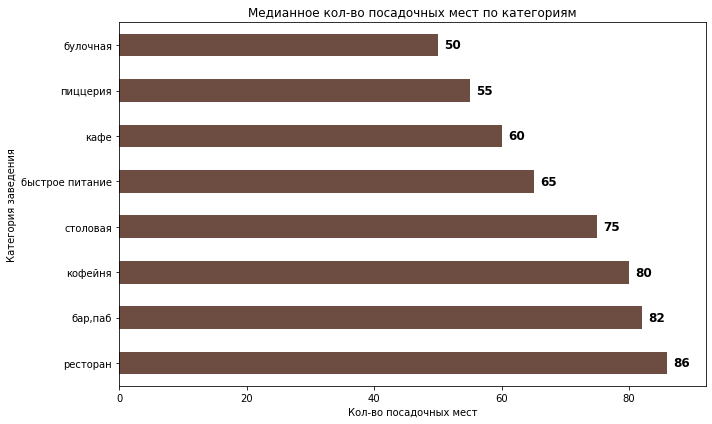

In [33]:
# Построим столбчатую диаграмму для визуализации полученных данных
ax = rest_cat_seats.plot(
    kind='barh',
    title='Медианное кол-во посадочных мест по категориям',
    color='#6D4C41',
    legend=False,
    xlabel='',
    figsize=(10, 6))

ax.set_xlabel('Кол-во посадочных мест')
ax.set_ylabel('Категория заведения')

for i, value in enumerate(rest_cat_seats['Медиана кол-ва мест']):
    ax.text(
        value + 1, i, int(value),
        ha='left', va='center',
        fontweight='bold', fontsize=12)

plt.xlim(right=92)
plt.tight_layout()
plt.show()

Наибольшее типичное количество посадочных мест наблюдается в ресторанах (86), барах/пабах (82) и кофейнях (80). Меньше всего мест в среднем по медиане приходится на булочные (50) и пиццерии (55).

<a id="section-3-5"></a>
### 3.5. Анализ рейтингов заведений


In [34]:
# Выведем информацию о среднем рейтинге по категориям заведений
rest_cat_rat = pd.DataFrame(
    rest.groupby('category')['rating']
    .mean()
    .sort_values(ascending=False)
    .round(2))

rest_cat_rat.columns = ['Средний рейтинг']
rest_cat_rat.index.name = 'Категория'

display(rest_cat_rat)

,Средний рейтинг
Категория,
"бар,паб",4.39
пиццерия,4.30
ресторан,4.29
кофейня,4.28
булочная,4.27
столовая,4.21
кафе,4.12
быстрое питание,4.05


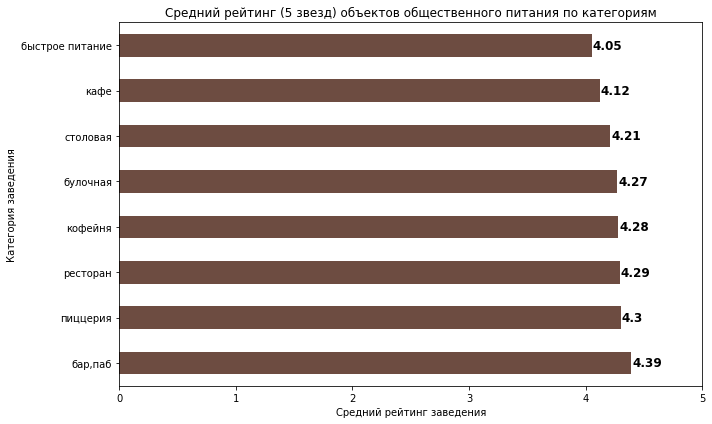

In [35]:
# Построим линейчатую диаграмму для визуализации полученных данных
ax = rest_cat_rat.plot(
    kind='barh',
    title='Средний рейтинг (5 звезд) объектов общественного питания по категориям',
    color='#6D4C41',
    legend=False,
    xlabel='',
    figsize=(10, 6))

ax.set_xlabel('Средний рейтинг заведения')
ax.set_ylabel('Категория заведения')

for i, value in enumerate(rest_cat_rat['Средний рейтинг']):
    ax.text(
        value + 0.01, i, round(value, 2),
        ha='left', va='center',
        fontweight='bold', fontsize=12)

plt.xlim(0, 5)
plt.tight_layout()
plt.show()

Средние рейтинги разных категорий различаются незначительно: значения находятся в диапазоне от 4.05 до 4.39, а разница между максимальным и минимальным средним рейтингом составляет 0.34 балла. Поэтому категория заведения сама по себе не связана с существенными различиями в пользовательских оценках.

<a id="section-3-6"></a>
### 3.6. Анализ факторов, связанных с рейтингом

In [36]:
# Выведем информацию о корреляци рейтинга с другими столбцами с использованием phi_k
corr_rating = rest[
    ['rating', 'category', 'district', 'chain', 'seats', 'price', 'is_24_7']
].phik_matrix()

corr_rating = (
    corr_rating.loc[corr_rating.index != 'rating', ['rating']]
    .sort_values(by='rating', ascending=False)
)

display(Markdown('**Связь рейтинга с характеристиками заведений по коэффициенту Phi-k**'))
display(corr_rating)

interval columns not set, guessing: ['rating', 'chain', 'seats']


**Связь рейтинга с характеристиками заведений по коэффициенту Phi-k**

,rating
price,0.262056
category,0.198815
district,0.189453
is_24_7,0.161010
chain,0.118785
seats,0.000000


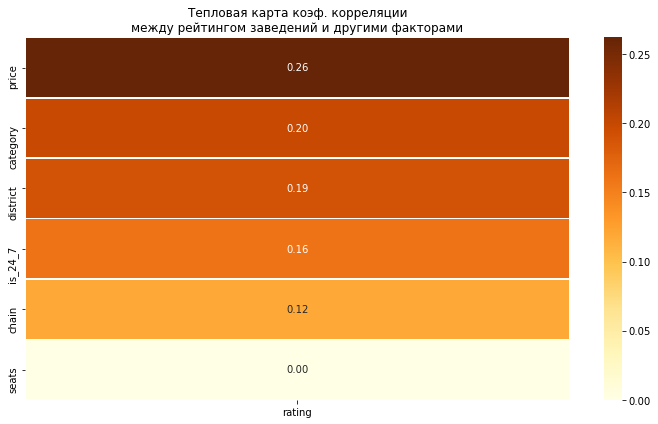

In [37]:
# Построим тепловую карту для коэффициента корреляции между рейтингом и другими столбцами
plt.figure(figsize=(10, 6))
sns.heatmap(data=corr_rating,
            annot=True,
            fmt='.2f',
            cmap='YlOrBr',
            linewidths=0.5)
plt.title('Тепловая карта коэф. корреляции\nмежду рейтингом заведений и другими факторами')
plt.tight_layout()
plt.show()

Наиболее сильная связь наблюдается между рейтингом и ценовой категорией — коэффициент Phi-k составляет 0.26. Связь остается слабой, поэтому говорить о сильной зависимости рейтинга от цены нельзя. Также небольшая связь наблюдается с категорией заведения (0.20) и административным округом (0.19).

Рассмотрим средние рейтинги заведений разных ценовых категорий, чтобы подробнее изучить наиболее заметную связь.

In [38]:
# Проверим самую сильную связь путем группировки заведений по категориям цен и выведем средний рейтинг для полученных групп
rest_corr_connection = pd.DataFrame(
    rest.groupby('price')['rating']
    .mean()
    .sort_values(ascending=False))

rest_corr_connection.columns = ['Средний рейтинг']
rest_corr_connection.index.name = 'Ценовая категория'

display(rest_corr_connection)

,Средний рейтинг
Ценовая категория,
высокие,4.436611
выше среднего,4.386347
средние,4.297874
низкие,4.173077


Средний рейтинг постепенно увеличивается вместе с ценовой категорией: у заведений с наиболее низкими ценами он составляет 4.17, а у заведений высокой ценовой категории — 4.44. Это подтверждает наличие положительной связи между ценовой категорией и рейтингом, однако по результатам корреляционного анализа эта связь остается слабой.

<a id="section-3-7"></a>
### 3.7. Анализ популярных сетей Москвы

In [39]:
# Выведем информацию о топ-15 сетей заведений по популярности (кол-ву)
# Для каждого из полученных заведений выведем средний рейтинг
# Отобразим, к каким категориям относится каждое заведение 
top15_names = (
    rest[rest['chain'] == True]
    .groupby('name')
    .agg({
        'id': 'count',
        'rating': 'mean',
        'category': 'unique'
    })
    .sort_values(by='id', ascending=False)
    .head(15))

top15_names.columns = ['Кол-во', 'Средний рейтинг', 'Категории']
top15_names['Средний рейтинг'] = top15_names['Средний рейтинг'].round(2)
top15_names['Категории'] = top15_names['Категории'].apply(lambda x: '; '.join(x))
top15_names.index.name = 'Сеть'

display(Markdown('**Топ-15 сетей Москвы по количеству заведений**'))
display(top15_names)

**Топ-15 сетей Москвы по количеству заведений**

,Кол-во,Средний рейтинг,Категории
Сеть,,,
шоколадница,120,4.18,кофейня; кафе
домино'с пицца,76,4.17,пиццерия
додо пицца,74,4.29,пиццерия
one price coffee,71,4.06,кофейня
яндекс лавка,69,3.87,ресторан
cofix,65,4.08,кофейня
prime,50,4.12,ресторан; кафе
хинкальная,44,4.32,быстрое питание; кафе; ресторан; столовая; бар...
кофепорт,42,4.15,кофейня


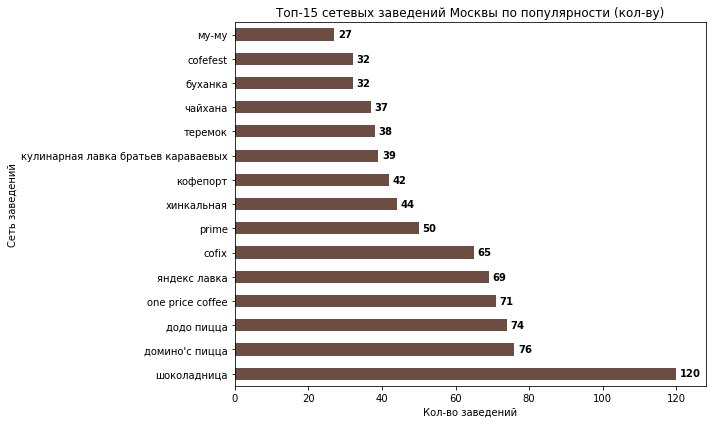

In [40]:
# Построим линейчатую диаграмму для визуализации топ-15 сетевых заведений по популярности
ax = top15_names['Кол-во'].plot(kind='barh', 
                           title='Топ-15 сетевых заведений Москвы по популярности (кол-ву)', 
                           color='#6D4C41', 
                           legend=False,
                           xlabel='',
                           figsize=(10, 6))
ax.set_xlabel('Кол-во заведений')
ax.set_ylabel('Сеть заведений')
for i, value in enumerate(top15_names['Кол-во'].values):
    ax.text(value + 1, i, int(value), 
            ha='left', va='center', 
            fontweight='bold', fontsize=10)
plt.xlim(right=128)
plt.tight_layout()
plt.show()

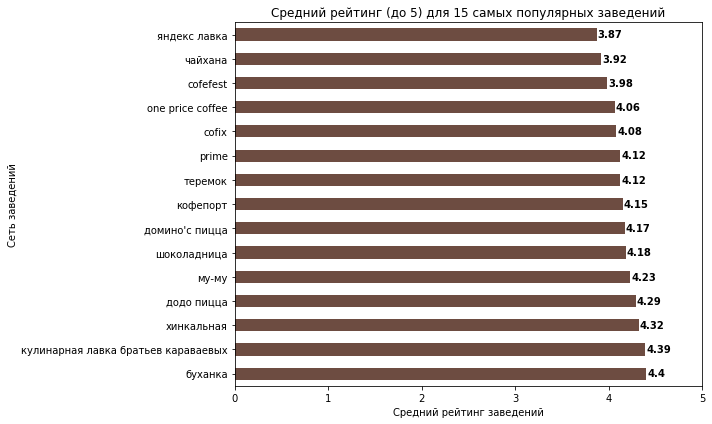

In [41]:
# Построим линейчатую диаграмму для визуализации среднего рейтинга для 15 самых популярных заведений
ax = top15_names['Средний рейтинг'].sort_values(ascending=False).plot(kind='barh', 
                           title='Средний рейтинг (до 5) для 15 самых популярных заведений', 
                           color='#6D4C41', 
                           legend=False,
                           xlabel='',
                           figsize=(10, 6))
ax.set_xlabel('Средний рейтинг заведений')
ax.set_ylabel('Сеть заведений')
for i, value in enumerate(top15_names['Средний рейтинг'].sort_values(ascending=False).values):
    ax.text(value + 0.01, i, round(float(value), 2), 
            ha='left', va='center', 
            fontweight='bold', fontsize=10)
plt.xlim(left=0)
plt.xlim(right=5)
plt.tight_layout()
plt.show()

Лидерами по количеству точек являются Шоколадница (120 заведений), Домино'с Пицца (76) и Додо Пицца (74). Среди наиболее распространенных сетей часто встречаются кофейни и пиццерии, при этом некоторые сети представлены сразу в нескольких категориях.

Самые высокие средние рейтинги среди топ-15 имеют Буханка (4.40), Кулинарная лавка братьев Караваевых (4.39) и Хинкальная (4.32). Наиболее низкие показатели среди рассматриваемых сетей — у Яндекс Лавки (3.87) и Чайханы (3.92).

<a id="section-3-8"></a>
### 3.8. Анализ среднего чека по административным округам Москвы

In [42]:
# Выведем таблицу со статистиками по среднему чеку в каждом АО Москвы
rest_avg_bill_stats = (
    rest.groupby('district')['middle_avg_bill']
    .agg([
        'mean',
        'std',
        ('q25', lambda x: x.quantile(0.25)),
        'median',
        ('q75', lambda x: x.quantile(0.75))
    ])
    .sort_values(by='mean', ascending=False)
    .round(2))

rest_avg_bill_stats.index.name = 'Административный округ'

display(Markdown('**Статистики среднего чека по административным округам Москвы**'))
display(rest_avg_bill_stats)

**Статистики среднего чека по административным округам Москвы**

,mean,std,q25,median,q75
Административный округ,,,,,
Центральный административный округ,1191.060059,920.01,500.00,1000.0,1500.0
Западный административный округ,1053.229980,779.01,427.50,1000.0,1500.0
Северный административный округ,927.960022,912.61,350.00,650.0,1250.0
Южный административный округ,834.400024,2008.64,350.00,500.0,1037.5
Северо-Западный административный округ,822.219971,595.06,340.00,700.0,1100.0
Восточный административный округ,820.630005,850.90,338.00,575.0,1100.0
Юго-Западный административный округ,792.559998,559.17,350.00,600.0,1100.0
Северо-Восточный административный округ,716.609985,591.23,325.00,500.0,950.0
Юго-Восточный административный округ,654.099976,566.83,281.25,450.0,887.5


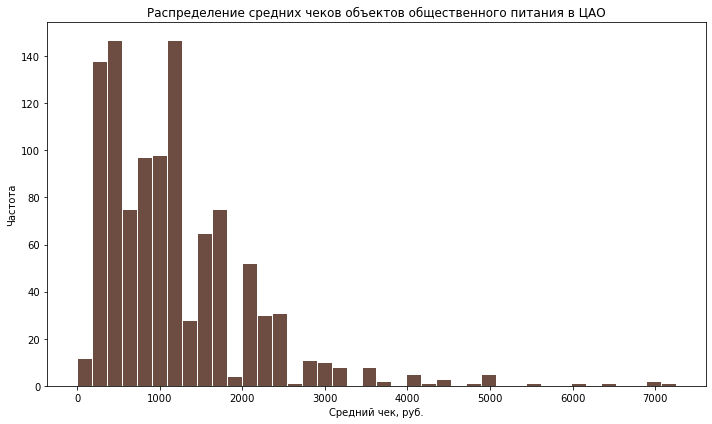

In [43]:
# Построим гистограмму распределения средних чеков в Центральном административном округе
rest[rest['district']=='Центральный административный округ']['middle_avg_bill'].plot(kind='hist',
                   title='Распределение средних чеков объектов общественного питания в ЦАО',
                   figsize=(10, 6),
                   color='#6D4C41',
                   edgecolor='white',
                   bins=40)
plt.xlabel('Средний чек, руб.')
plt.ylabel('Частота')
plt.tight_layout()
plt.show()

Распределение среднего чека в ЦАО имеет выраженный правосторонний скос и содержит высокие значения. Медианный средний чек составляет 1000 руб., а стандартное отклонение — около 920 руб., что указывает на заметный разброс цен среди заведений в центре Москвы.

Сравним распределение среднего чека в ЦАО с другими административными округами.

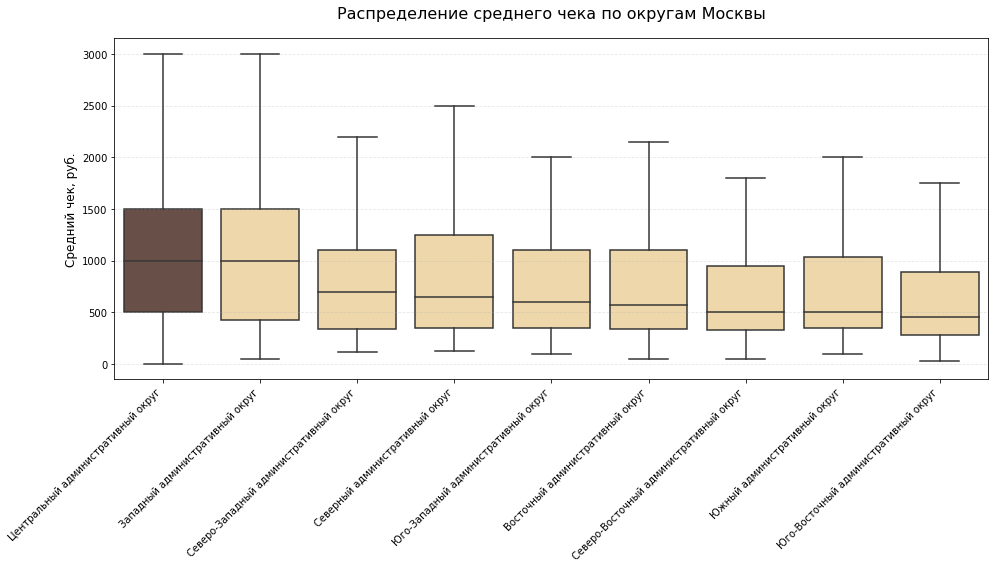

In [44]:
# Построим ящики с усами для каждого административного округа, чтобы сравнить размах значений средних чеков
plt.figure(figsize=(14, 8))
medians = rest.groupby('district')['middle_avg_bill'].median()
target_district = 'Центральный административный округ' 
other_districts = medians.drop(target_district).sort_values(ascending=False).index.tolist()
sorted_districts = [target_district] + other_districts
colors = ['#6D4C41', '#f8daa0', '#f8daa0', '#f8daa0', '#f8daa0', '#f8daa0', '#f8daa0', '#f8daa0', '#f8daa0']
sns.boxplot(data=rest, x='district', y='middle_avg_bill', showfliers=False, palette=colors, order=sorted_districts)
plt.title('Распределение среднего чека по округам Москвы', fontsize=16, pad=20)
plt.ylabel('Средний чек, руб.', fontsize=12)
plt.xlabel('')
plt.xticks(rotation=45, ha='right') 
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

Центральный административный округ выделяется одним из самых высоких уровней среднего чека: медиана составляет 1000 руб., а верхний квартиль — около 1500 руб. Для сравнения, медианные значения в Северо-Восточном и Юго-Восточном округах составляют около 500 и 450 руб. соответственно.

При этом высокий уровень среднего чека характерен не только для центра: западные округа также находятся среди лидеров. Поэтому по имеющимся данным нельзя утверждать о равномерном снижении цен по мере удаления от центра. Скорее наблюдаются различия между отдельными направлениями Москвы, при этом ЦАО остается одним из наиболее дорогих округов.

---

### Промежуточный вывод

В выборке преобладают кафе, рестораны и кофейни, а наибольшая концентрация заведений наблюдается в Центральном административном округе. Большинство заведений являются несетевыми, однако среди булочных, пиццерий и кофеен доля сетевых точек превышает 50%.

Типичное количество посадочных мест зависит от категории: наиболее высокие медианные значения наблюдаются у ресторанов, баров/пабов и кофеен. Средние рейтинги разных категорий отличаются незначительно. Наиболее заметная связь рейтинга среди рассмотренных признаков наблюдается с ценовой категорией, однако и она остается слабой.

ЦАО выделяется высоким уровнем среднего чека, при этом заметные различия наблюдаются и между другими административными округами Москвы.

---

<a id="section-4"></a>
## 4. Итоговые выводы и рекомендации

На основе проведенного анализа подведем основные итоги исследования рынка общественного питания Москвы и сформулируем рекомендации, которые могут быть полезны при выборе концепции будущего заведения.

<a id="section-4-1"></a>
### Результаты проведенного анализа

В исследовании проанализированы данные о 8402 заведениях общественного питания Москвы. Рассматривались категории и расположение заведений, распространенность сетевого формата, количество посадочных мест, рейтинги и ценовые характеристики.

Перед проведением анализа были изучены типы данных и пропуски, нормализованы названия и адреса заведений, удалены 3 дубликата и создан признак круглосуточной работы. Пропущенные значения было решено не заполнять искусственно, поскольку для части признаков они связаны со структурой исходных данных, а для остальных отсутствует обоснованный способ восстановления.

В ходе исследовательского анализа были изучены структура рынка, различия между категориями и административными округами, особенности сетевых заведений, распределение посадочных мест и среднего чека, а также связь рейтинга с характеристиками заведений.

<a id="section-4-2"></a>
### Основные выводы

Наиболее распространенными форматами общественного питания в Москве являются кафе, рестораны и кофейни. Кафе занимают первое место и составляют около 28% всех заведений в выборке.

Наибольшая концентрация заведений наблюдается в Центральном административном округе — 2242 объекта, что примерно в 2.5 раза больше, чем в Северном административном округе, занимающем второе место. В самом ЦАО наиболее распространены рестораны (670 заведений) и кафе (464).

Большинство заведений Москвы являются несетевыми: на сетевой формат приходится 38% выборки. При этом среди булочных (61%), пиццерий (52%) и кофеен (51%) доля сетевых заведений превышает половину. Самыми распространенными сетями являются Шоколадница (120 точек), Домино'с Пицца (76) и Додо Пицца (74).

Типичное количество посадочных мест различается в зависимости от категории. Наибольшие медианные значения наблюдаются у ресторанов (86 мест), баров/пабов (82) и кофеен (80), а наименьшие — у булочных (50) и пиццерий (55).

Средние рейтинги категорий отличаются незначительно и находятся в диапазоне от 4.05 до 4.39. Наиболее заметная связь рейтинга среди рассмотренных характеристик наблюдается с ценовой категорией, однако коэффициент Phi-k составляет только 0.26, поэтому эта связь остается слабой.

Центральный административный округ относится к наиболее дорогим по уровню среднего чека: его медианное значение составляет 1000 руб. При этом заметные различия наблюдаются и между остальными округами, поэтому однозначной зависимости среднего чека от расположения относительно центра по имеющимся данным установить нельзя.

<a id="section-4-3"></a>
### Рекомендации

Полученные результаты можно использовать как ориентиры при дальнейшем выборе концепции заведения.

ЦАО представляет интерес за счет высокой концентрации заведений и одного из наиболее высоких уровней среднего чека. Одновременно большое количество объектов говорит о высокой насыщенности рынка, поэтому перед выбором конкретной локации потребуется отдельный анализ конкурентов и потенциального спроса.

При выборе формата стоит обратить внимание на кофейни и пиццерии: в этих категориях сетевой формат уже получил широкое распространение, его доля составляет 51% и 52% соответственно. В то же время высокая представленность формата не доказывает его инвестиционную привлекательность, поэтому окончательный выбор должен учитывать уровень конкуренции, затраты и ожидаемую выручку.

Количество посадочных мест стоит определять с учетом выбранной категории. В исследованных данных медианное значение составляет около 80 мест для кофеен, 55 для пиццерий и 86 для ресторанов, что можно использовать как первоначальный ориентир при поиске помещения.

Ценовую категорию не стоит выбирать только на основании ее связи с рейтингом: более дорогие заведения действительно имеют несколько более высокие средние оценки, однако выявленная связь является слабой.

Для принятия окончательного инвестиционного решения анализ стоит дополнить данными о посещаемости и спросе, стоимости аренды, среднем количестве заказов, выручке, расходах и рентабельности заведений, а также более детальной информацией о конкретных локациях и конкурентах.